<a href="https://colab.research.google.com/github/Abdoulaye279/Financial-Engineering/blob/main/var-es-sp500/02_sp500_backtest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 - Backtest of 5 VaR/ES models on the S&P 500

1-day VaR and ES at 99%. Each day, models only see the last 1000 days; GARCH refitted every 250 days. Kupiec: is the breach rate 1%? Christoffersen: are breaches independent?

In [1]:
# colab: get the repo first
try:
    import google.colab
    !git clone -q https://github.com/Abdoulaye279/Financial-Engineering
    %cd Financial-Engineering/var-es-sp500
except ImportError:
    pass

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from risk import *

spx = load_close("../black-scholes-sp500/data/sp500.csv").loc["2000":]
rets = np.log(spx).diff().dropna()
len(rets), rets.index[0].date(), rets.index[-1].date()

(6761, datetime.date(2000, 1, 4), datetime.date(2026, 11, 19))

In [3]:
bt = backtest(rets, alpha=0.99, window=1000, refit=250)
names = {"normal": "normal", "hist": "historical", "garch": "garch", "gt": "garch student-t", "fhs": "FHS", "evt": "garch-EVT"}
def summary(bt, models):
    for m in models:
        breach = bt["ret"] < -bt[f"var_{m}"]
        ratio = (-bt["ret"][breach]).mean() / bt[f"es_{m}"][breach].mean()
        print(f"{names[m]:17s} {breach.sum():4d} breaches ({100*breach.mean():.2f}%)  "
              f"kupiec p={kupiec(breach.values)[1]:.3f}  christoffersen p={christoffersen(breach.values)[1]:.3f}  "
              f"loss/ES={ratio:.2f}")

print(len(bt), "days, expected", round(0.01 * len(bt)), "breaches")
summary(bt, names)
# normal      2.3%, rejected by both tests, losses on breach days 39% above its ES
# historical  1.5%, still rejected and breaches come in clusters (4-year window too slow in a crisis)
# garch       independent breaches now, but 2.2%: the normal tail is too thin
# garch-t     better (1.5%, ES right) but still rejected: the t is symmetric and the losses are not (see below)
# FHS         passes both
# garch-EVT   closest to 1%, ES right, christoffersen p = 0.047 just under 5%

5761 days, expected 58 breaches
normal             135 breaches (2.34%)  kupiec p=0.000  christoffersen p=0.000  loss/ES=1.39
historical          84 breaches (1.46%)  kupiec p=0.001  christoffersen p=0.000  loss/ES=1.07
garch              129 breaches (2.24%)  kupiec p=0.000  christoffersen p=0.527  loss/ES=1.12
garch student-t     88 breaches (1.53%)  kupiec p=0.000  christoffersen p=0.210  loss/ES=1.01
FHS                 71 breaches (1.23%)  kupiec p=0.087  christoffersen p=0.070  loss/ES=1.03
garch-EVT           66 breaches (1.15%)  kupiec p=0.278  christoffersen p=0.047  loss/ES=1.03


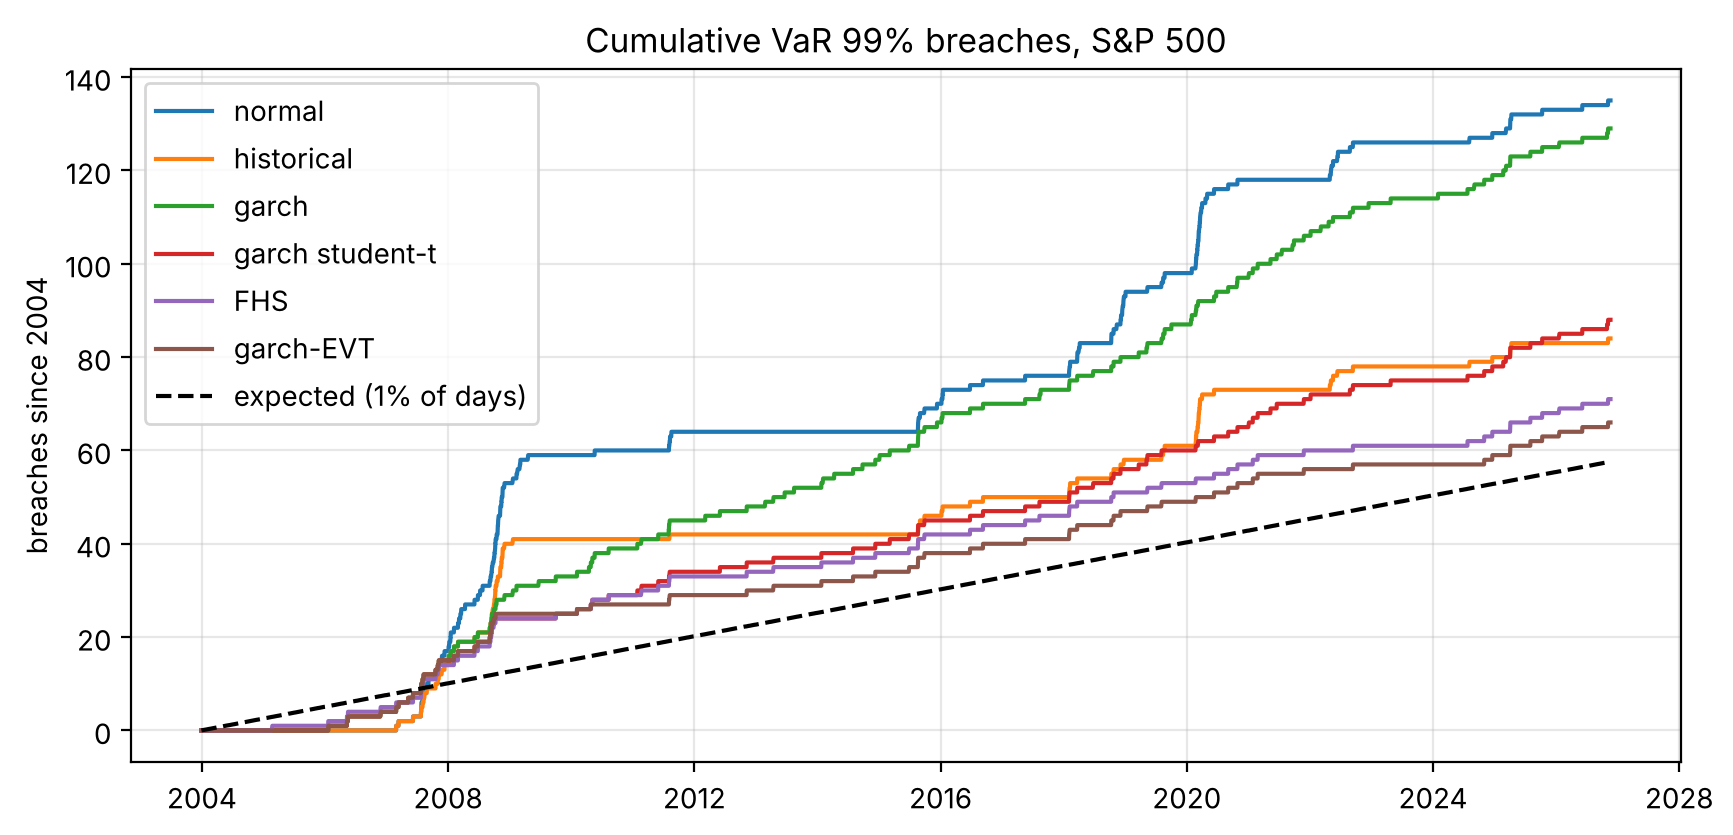

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for m in names:
    breach = bt["ret"] < -bt[f"var_{m}"]
    ax.plot(breach.cumsum(), label=names[m])
ax.plot(bt.index, 0.01 * np.arange(1, len(bt) + 1), "k--", label="expected (1% of days)")
ax.set_ylabel("breaches since 2004")
ax.set_title("Cumulative VaR 99% breaches, S&P 500")
ax.grid(alpha=0.3)
ax.legend()
plt.show()
# normal and historical jump in 2007-08, 2018 (feb vol spike) and 2020
# garch: no jumps but too steep all the time. FHS / EVT jump in 2008 then follow the 1% line

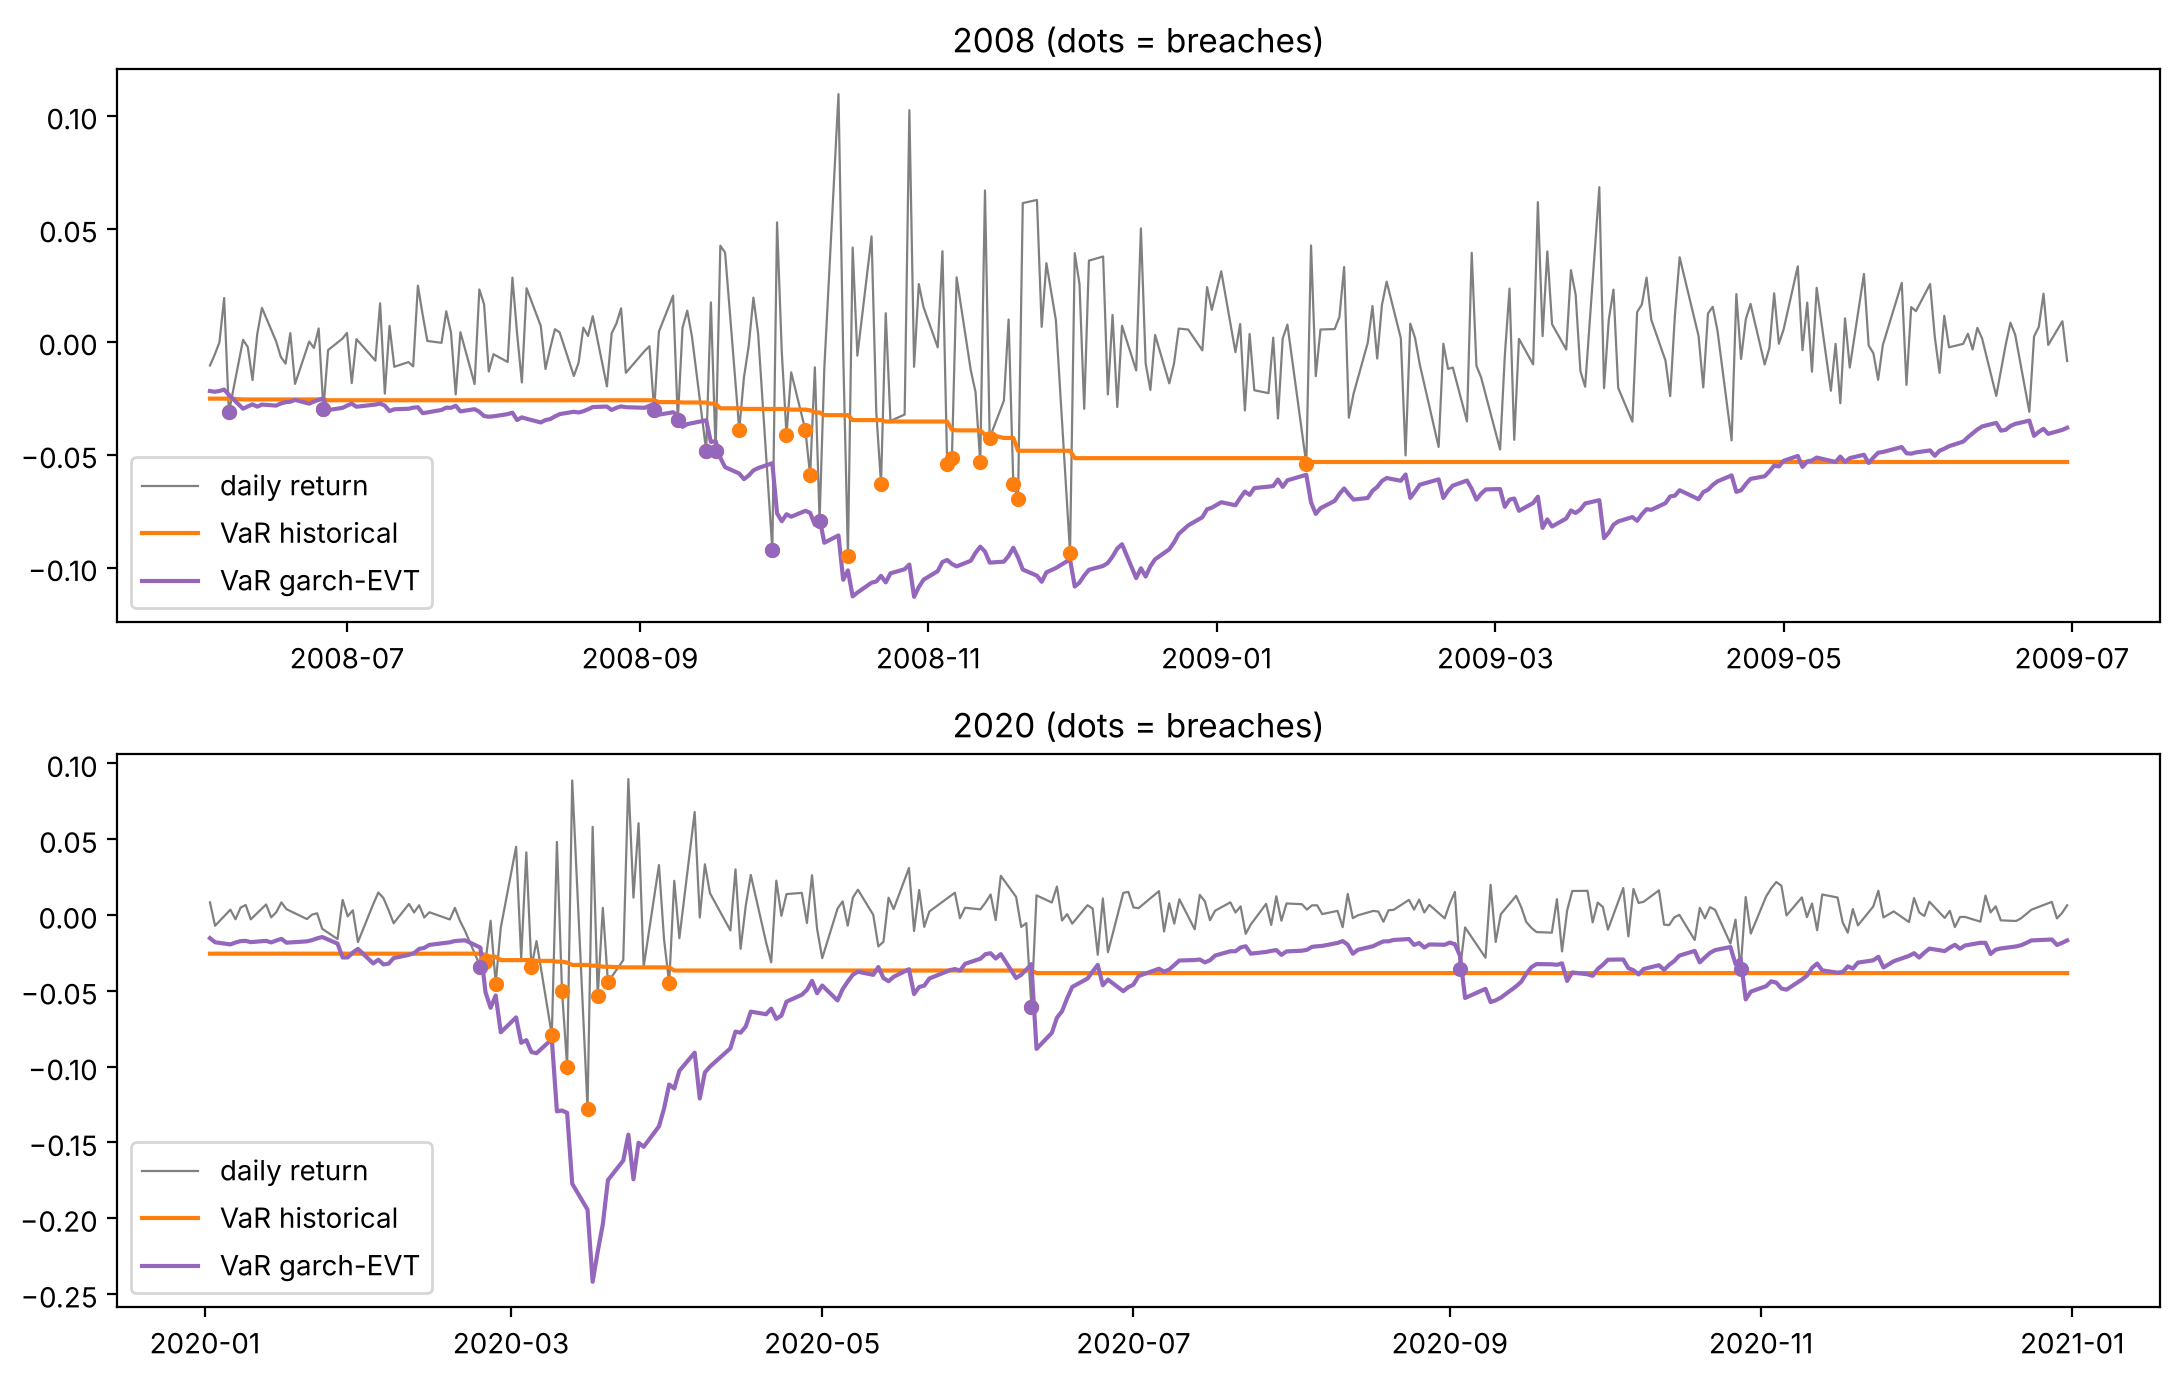

max garch-EVT VaR in 2020: 0.242  worst day: -0.128


In [5]:
fig, ax = plt.subplots(2, 1, figsize=(11, 7))
for axis, (start, end) in zip(ax, [("2008-06-01", "2009-06-30"), ("2020-01-01", "2020-12-31")]):
    p = bt.loc[start:end]
    axis.plot(p.index, p["ret"], color="grey", lw=0.8, label="daily return")
    for m, color in [("hist", "C1"), ("evt", "C4")]:
        axis.plot(p.index, -p[f"var_{m}"], color=color, label=f"VaR {names[m]}")
        br = p["ret"] < -p[f"var_{m}"]
        axis.scatter(p.index[br], p["ret"][br], color=color, s=20, zorder=3)
    axis.set_title(f"{start[:4]} (dots = breaches)")
    axis.legend(loc="lower left")
plt.tight_layout()
plt.show()
print("max garch-EVT VaR in 2020:", round(bt.loc["2020", "var_evt"].max(), 3), " worst day:", round(bt.loc["2020", "ret"].min(), 3))
# historical VaR almost flat -> breached again and again during the crash, then too high for years after
# EVT VaR widens right after the first big losses. but it overreacts too: 24% in march 2020 vs a worst day of -12.8%

In [6]:
# why garch student-t still has too many breaches
o, a_, b_, nu = garch_t_fit(rets.values)
x = rets.values - rets.mean()
z = x / np.sqrt(garch_filter(x, o, a_, b_)[:-1])
k = np.sqrt((nu - 2) / nu)
print("nu", round(nu, 1), " residual skew", round(stats.skew(z), 2))
print("1% quantile: residuals", round(np.quantile(z, 0.01), 2), " t", round(stats.t.ppf(0.01, nu) * k, 2))
print("99% quantile: residuals", round(np.quantile(z, 0.99), 2), " t", round(stats.t.ppf(0.99, nu) * k, 2))
# the t fits both tails at once: -2.55 / +2.55, but the data is -2.75 on the loss side and only +2.19 on the gain side
# -> too optimistic on losses. FHS and EVT take the left tail from the data, that's why they pass
# next step would be a skewed t (Hansen 1994) or a GJR-GARCH where bad days raise the vol more than good days

nu 6.4  residual skew -0.58
1% quantile: residuals -2.75  t -2.55
99% quantile: residuals 2.19  t 2.55
